### Daten anaylse
- Welche Variablen beeinflussen Bodenatmung (soil.res) .

In [70]:
hainich.data <- read.csv("/Users/anshulkhubchandani/Documents/2teSem-Master/stat/statistik/hainich.csv", sep=";")
#str(hainich.data)
#summary(hainich.data)
head(hainich.data)



,soil.res,temp.0,temp.5,temp.10,temp.15,smoi,lmoi,litter.d,ph.litter,ph.soil0,⋯,litno3,litnh4,litdoc,sno30,snh40,sdoc0,sno35,snh45,sdoc5,nn
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4.3750,15.52,11.91,11.79,11.74,41.75939,0.6782141,0.3,6.45,4.23,⋯,0.036393668,0.018885578,0.4684278,0.01070368,0.002945600,0.09095835,0.004000000,0.003130156,0.11875886,2.49
2,4.3425,11.75,11.54,11.41,11.40,32.72151,0.5684457,1.5,6.42,4.30,⋯,0.002000000,0.003346766,0.3854520,0.00500000,0.003632943,0.08783729,0.004000000,0.001853513,0.05462559,1.06
3,2.9800,12.61,11.75,11.52,11.48,33.83690,0.6595609,1.0,6.32,4.27,⋯,0.017632441,0.004607981,0.3919999,0.01760351,0.002377711,0.06770848,0.014260353,0.002639287,0.04153205,1.58
4,2.5625,11.75,11.40,11.35,11.26,28.25263,0.5779671,1.5,5.74,3.90,⋯,0.016701030,0.006571442,0.3751276,0.01089270,0.002118255,0.09349080,0.013633983,0.002255407,0.05857811,1.36
5,2.6000,12.29,11.59,11.45,11.39,42.87905,0.6757647,1.5,6.24,4.05,⋯,0.007461533,0.010068415,0.5004978,0.02276019,0.008599232,0.06802427,0.014321943,0.001674059,0.04704889,2.77
6,6.2125,12.93,11.74,11.59,11.50,27.27465,0.6292582,2.0,5.54,4.23,⋯,0.038616580,0.017991253,0.7431942,0.01743749,0.008957436,0.08329230,0.006601767,0.001000000,0.05974198,1.60


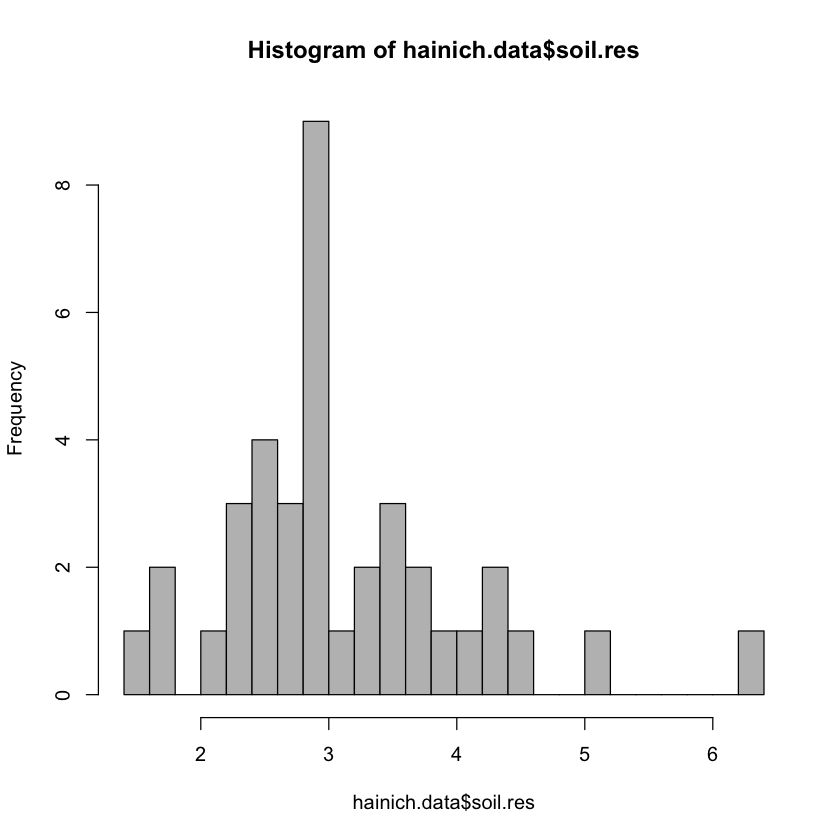

[1] 3.113026

[1] 2.9225

[1] 0.9041724

[1] 8.541006

[1] 0.3054519

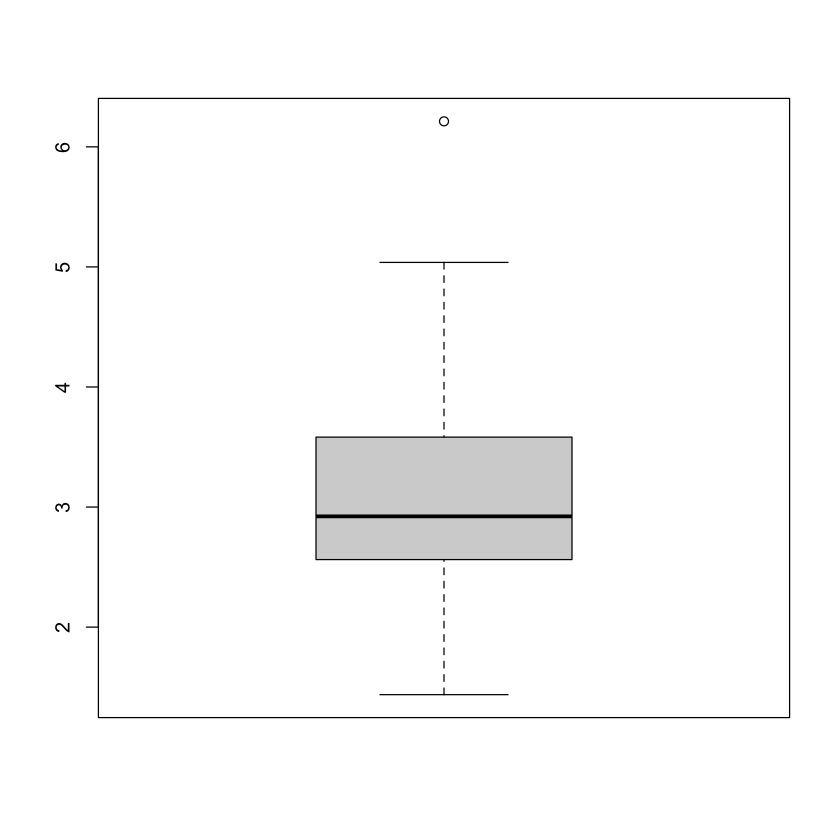

In [ ]:
hist(hainich.data$soil.res, breaks=20, col="grey")
boxplot(hainich.data$soil.res)
mean(hainich.data$soil.res)
median(hainich.data$soil.res)
var(hainich.data$soil.res)
median(hainich.data$soil.res)^2

#Varianzkoeff
sd(hainich.data$soil.res) / mean(hainich.data$soil.res) # 0.305 -> moderate sreung
# Varianz ist viel kleiner als Median^2

### Histogramm
- keine Gleichverteilung
- keine starke normakverteilung abeeer annährend glockenforme?
- mögliche ausreßer rechts?????
### Boxplot
- Median ≈ 2.9 -3
- Die mittleren 50% der Werte liegen ungefähr zwischen 2.6 und 3.6
- Es gibt einige größere Werte (rechts) → mögliche hohe Bodenatmung

- Daten sind:
    - leicht rechts-schief (Die meisten Werte links/mittig aber einige großere werte weit rechts), mean> median -> rechts-schief
    - Streuung moderat, 
    - Paar hohe Werte könnten ökologisch wichtig sein?

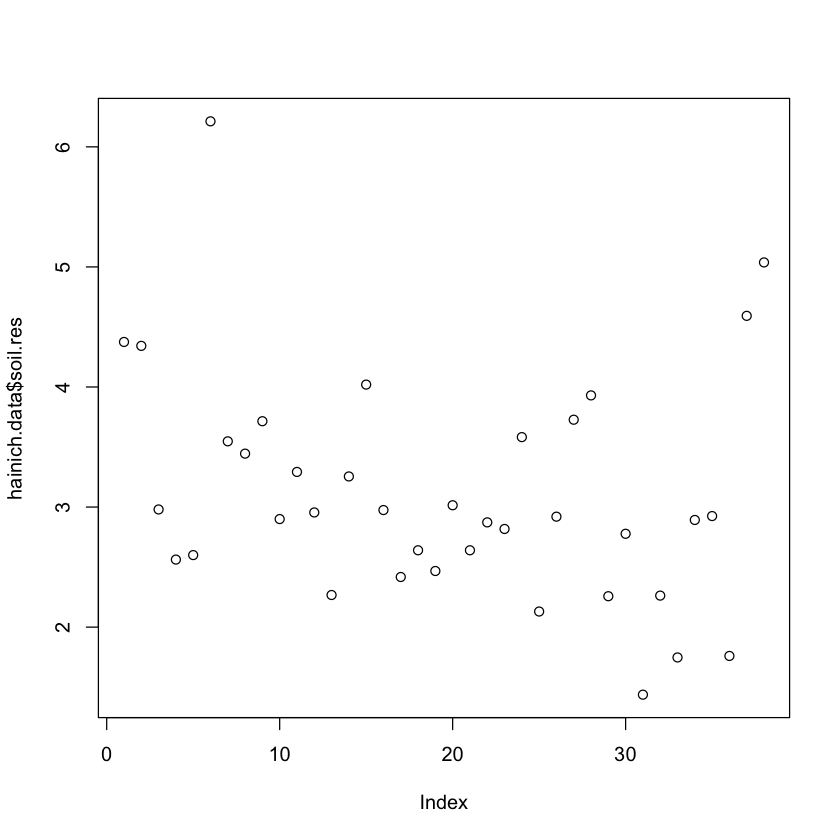

In [ ]:
#Varianz überprufen
plot(hainich.data$soil.res)


### Normalverteilung
-> nicht normalverteilt

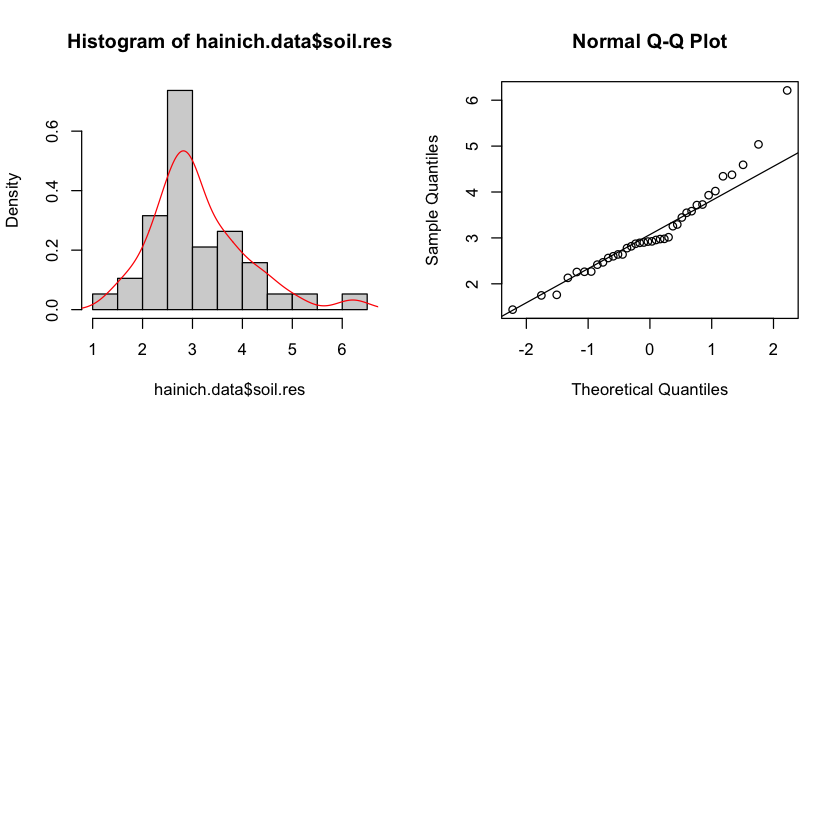

In [66]:
par(mfrow=c(2,2))
#Test aud normalverteilung
hist(hainich.data$soil.res, prob=TRUE)
lines(density(hainich.data$soil.res), col="red")

qqnorm(hainich.data$soil.res)
qqline(hainich.data$soil.res)
#nope nicht perf normal

### Transformation der Daten

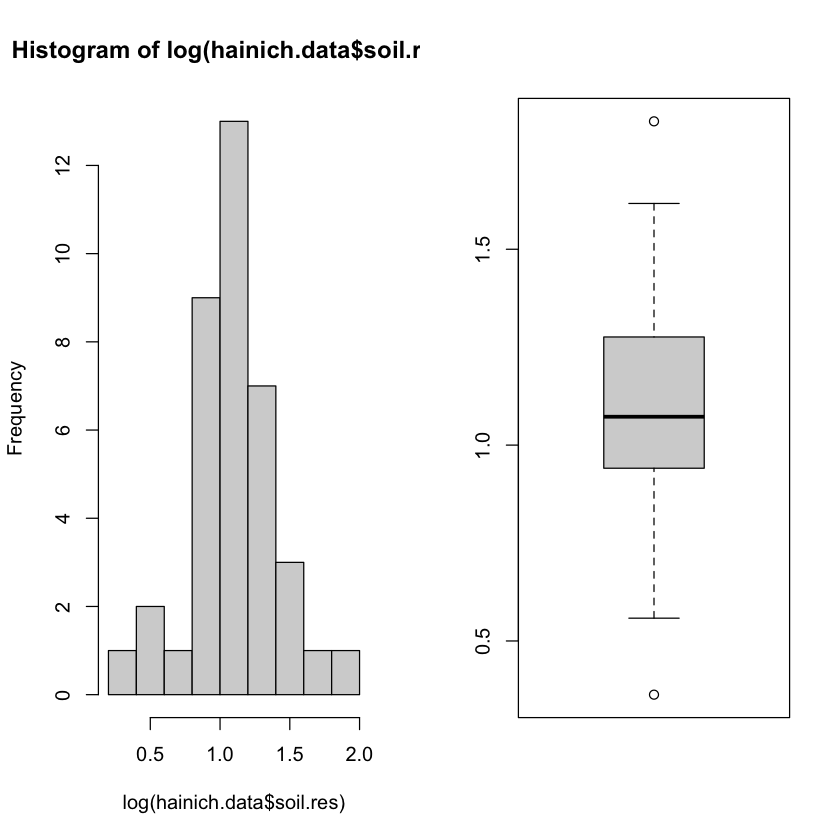

In [88]:
par(mfrow=c(1,2))
hist(log(hainich.data$soil.res))
boxplot(log(hainich.data$soil.res))

- log transf reduziert schiefe
- Median etwa in der Mitte der Box → symmetrisch

sqrt tranfs -> no

### Lognormal- vert
Punkte liegen deutlich näher an der Linie -> besser!

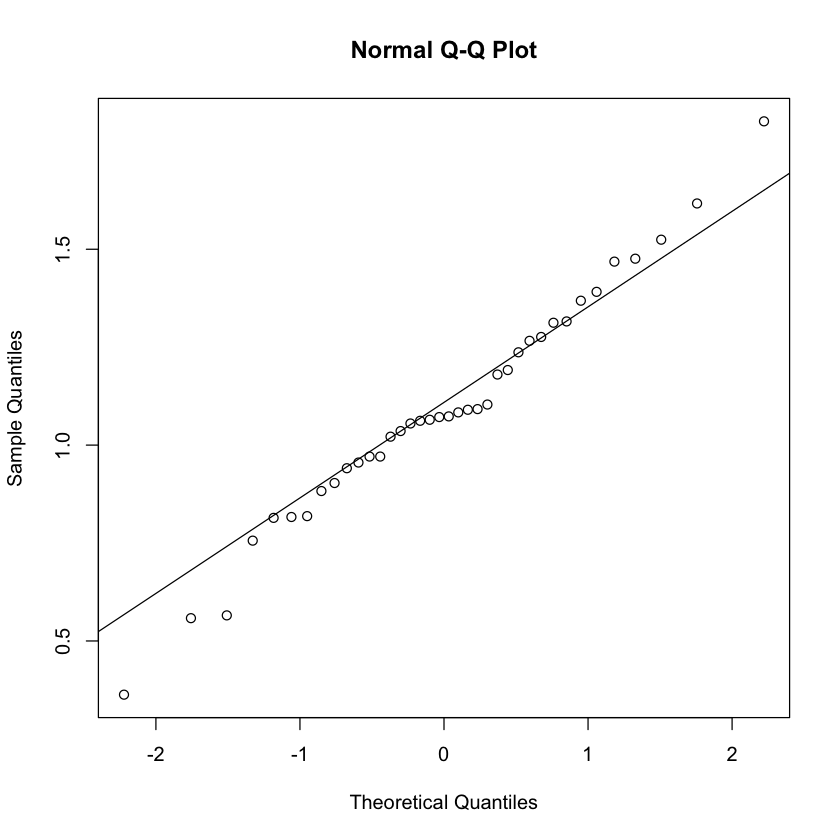

In [ ]:
qqnorm(log(hainich.data$soil.res))
qqline(log(hainich.data$soil.res))



# Annahmen:
- Transformation: log
    - y <- log(hainich.data$soil.res)
    - Log(soil.res) 
    - soil.res > 0 
- Verteilung: Lognormal
    - Wenn log(Y) normalverteilt ist → Y ist lognormal. log(soil.res) ≈ normal 
    - Alternativ Gamma?

### Scatterplotts
- wichtigste einflussgrößen


In [ ]:
y <- log(hainich.data$soil.res)

[1] 1.4759065 1.4684502 1.0919233 0.9409833 0.9555114 1.8265634 1.2662431
 [8] 1.2369239 1.3123787 1.0647107 1.1916472 1.0834987 0.8186779 1.1801923
[15] 1.3912819 1.0902440 0.8827339 0.9707789 0.9032055 1.1035998 0.9707789
[22] 1.0551827 1.0358500 1.2760609 0.7561220 1.0715836 1.3157378 1.3686394
[29] 0.8142580 1.0215512 0.3629055 0.8164704 0.5581862 1.0621212 1.0732945
[36] 0.5653138 1.5244245 1.6169099

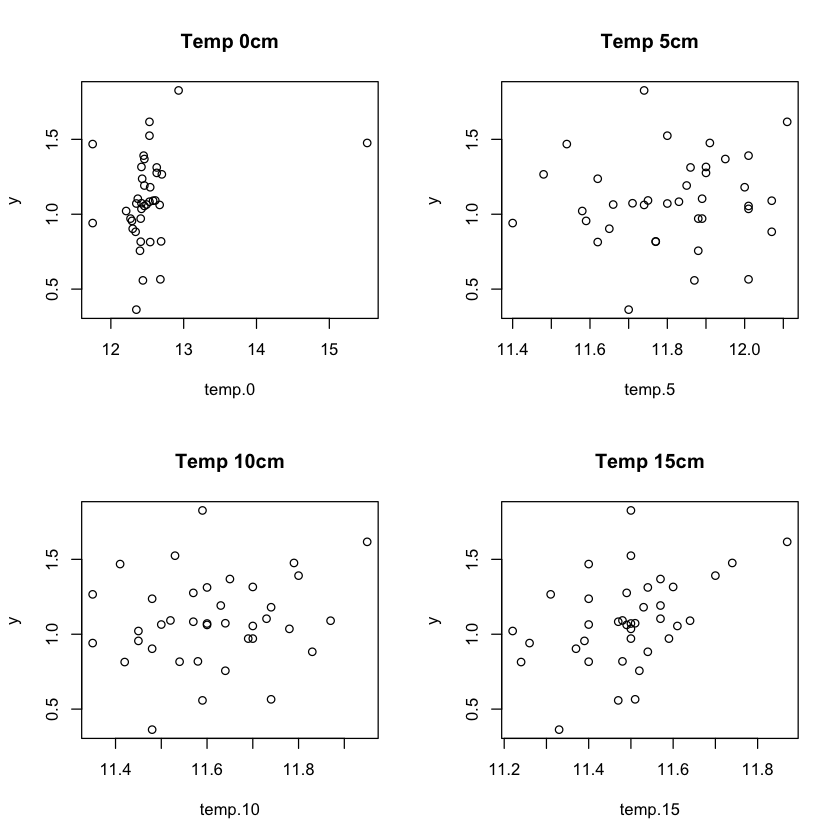

In [94]:
#Temperatur vs Bodenatmung
par(mfrow=c(2,2))
plot(y ~ temp.0, hainich.data, main="Temp 0cm")
plot(y ~ temp.5, hainich.data, main="Temp 5cm")
plot(y ~ temp.10, hainich.data, main="Temp 10cm")
plot(y ~ temp.15, hainich.data, main="Temp 15cm")


- Temperaturen liegen etwa 12–13.5 °C
- An der Oberfläche ist die temperatur ≈ gleich und bodenatmung sehr unterschiedlich -> oberflächetemp erklärt y nicht gut -> sonne wind etc
- temp 5 cm -> mehr temp unterschiede, leichter steigung, ~ mehr temp mehr bodenarmung -> hier leben mikroorgnaismen
- temp 10 cm -> temp ist stabiler? postive zsmhg
- temp 15 -> positiver trend
- je tiefer desto klarer den zsmhg

- Bio: Höhere Temperatur → mehr mikrobielle Aktivität → mehr CO₂ → höhere Bodenatmung

- postiver zhmg, moderate korrelation aber viele punkte streuen dh temp ist nicht das einzige faktor!

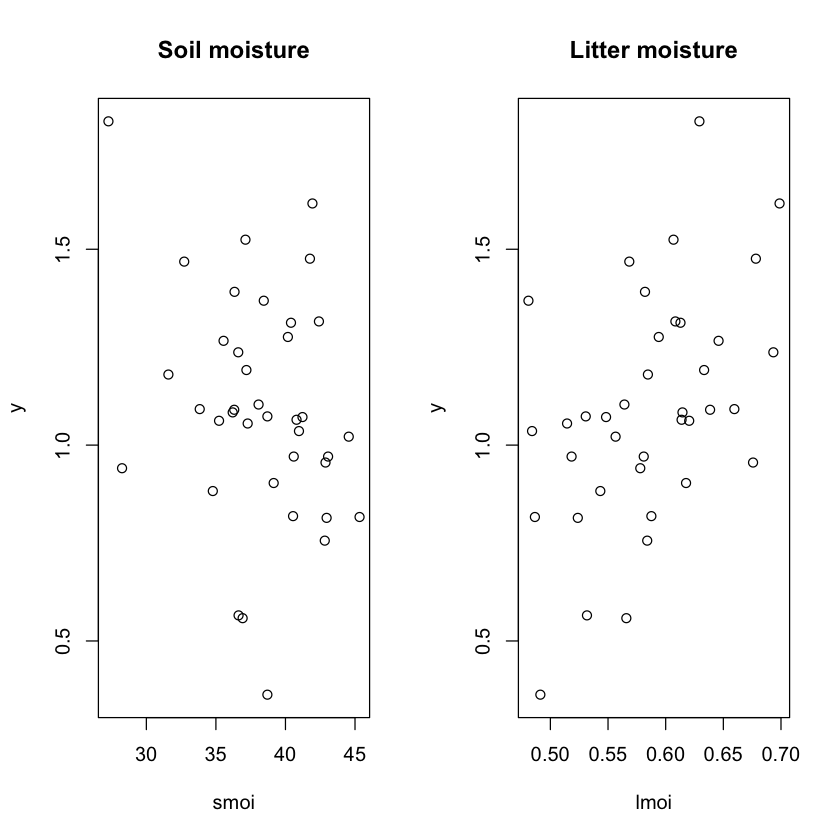

In [95]:
#Bodenfeuchte vs Bodenatmung
par(mfrow = c(1, 2))
plot(y ~ smoi, hainich.data, main="Soil moisture")
plot(y ~ lmoi, hainich.data, main="Litter moisture")

- smoi = soil moisture (Bodenfeuchte) 
	- Bodenatmung ist bei mittlerer Feuchte am höchsten
	- Bei sehr niedriger oder sehr hoher Feuchte eher niedrigere Werte ->  ∩-Form Parabel

- lmoi = litter moisture (Feuchte der Streuschicht) 
	- Zusammenhang stärker als bei smoi
	- Bodenatmung stegt mit smoi, aber bei sehr hoher Feuchte wieder Streuung / evtl. Sättigung
	- Streuschicht ist wichtig Feuchte steuert Aktivität direkt (lmoi kann ein starker Prädiktor sein)

In [ ]:
y <- log(hainich.data$soil.res)

par(mfrow=c(2,3))

plot(y ~ temp.0, hainich.data, main="Temp 0cm")
plot(y ~ smoi, hainich.data, main="Soil moisture")
plot(y ~ rootdw0, hainich.data, main="Root biomass")
plot(y ~ soiln0, hainich.data, main="Soil nitrogen")
plot(y ~ soilc0, hainich.data, main="Soil carbon")
plot(y ~ ph.soil0, hainich.data, main="Soil pH")

[1] 6

[1] 6.2125

In [98]:
vars <- c("temp.15","smoi","rootdw5","soiln0","soilc0","ph.soil0")

cor(y, hainich.data[,vars])

temp.15,smoi,rootdw5,soiln0,soilc0,ph.soil0
0.4348038,-0.259031,0.2464194,0.3260894,0.2297989,0.1516593
